# 03 - Reward ablation + sim-side validation

Headline figures for the masters defence. See `README.md` for the project narrative; this notebook only owns the four plots + their underlying numbers.

**Cohort**: `reward_ablation_5min` MLflow experiment, pinned via `artifacts/cohort_run_ids.json` (regenerate with `python tools/derive_cohort.py` after every sweep).

**Prerequisites** (run from repo root before opening this notebook):

```bash
bash tools/run_ablation.sh                            # ~2 hr - 12 SAC runs
python tools/derive_cohort.py                         # pin cohort
biolistener-sleep eval --checkpoint app/agent/checkpoints/sac_full_shaped_seed3_<...>.zip \
    --n 100 --episode-s 300 --out artifacts/full_shaped_rollouts.parquet   # ~30 min
biolistener-sleep shield-test --episodes 10000 --out artifacts/shield_log.json   # ~30 s
```


## Setup


In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
print("cwd:", Path.cwd())

# MLflow store.
mlflow.set_tracking_uri('sqlite:///' + str(Path('mlflow.db').resolve()))
EXPERIMENT = 'reward_ablation_5min'   # 5-min episode cohort (matches sleep-onset latency)

# Cohort filter
cohort_path = Path('artifacts/cohort_run_ids.json')
assert cohort_path.exists(), (
    f'{cohort_path} missing - run `python tools/derive_cohort.py` after '
    'finishing tools/run_ablation.sh.'
)
COHORT_BY_VARIANT = json.loads(cohort_path.read_text())
COHORT_IDS = {rid for ids in COHORT_BY_VARIANT.values() for rid in ids}
print(f'Cohort filter: {len(COHORT_IDS)} runs across {len(COHORT_BY_VARIANT)} variants')
for v, rids in COHORT_BY_VARIANT.items():
    print(f'  {v:<22s} {len(rids)} runs')

client = mlflow.tracking.MlflowClient()
exp = client.get_experiment_by_name(EXPERIMENT)
assert exp is not None, f'No MLflow experiment {EXPERIMENT!r} - run tools/run_ablation.sh first.'
all_runs = mlflow.search_runs(experiment_ids=[exp.experiment_id], max_results=500)
runs = all_runs[all_runs['run_id'].isin(COHORT_IDS)].copy()
print(f'\nLoaded {len(runs)} / {len(all_runs)} runs (after cohort filter)')
runs[['tags.reward_variant', 'params.seed', 'params.total_steps',
      'metrics.sac_eval_mean']].sort_values('tags.reward_variant')

cwd: /second_ssd/study/adaptive_neuro_stimulation_sleep
Cohort filter: 12 runs across 4 variants
  naive_alpha_max        3 runs
  naive_plv_only         3 runs
  theta_alpha_delta      3 runs
  full_shaped            3 runs



Loaded 12 / 13 runs (after cohort filter)


,tags.reward_variant,params.seed,params.total_steps,metrics.sac_eval_mean
0,full_shaped,3,100000,101.931631
1,full_shaped,2,100000,103.063717
2,full_shaped,1,100000,290.646708
9,naive_alpha_max,3,30000,450.285298
10,naive_alpha_max,2,30000,224.501011
11,naive_alpha_max,1,30000,273.761887
6,naive_plv_only,3,30000,288.581593
7,naive_plv_only,2,30000,283.320743
8,naive_plv_only,1,30000,293.452062
3,theta_alpha_delta,3,30000,32.827721


## A. Training curves per variant

One panel per variant. **Y-axes NOT comparable across panels** - each reward function pays different terms, so the numbers don't translate. These confirm within-variant training stability only; cross-variant comparison happens via shared task metrics in the next plot.


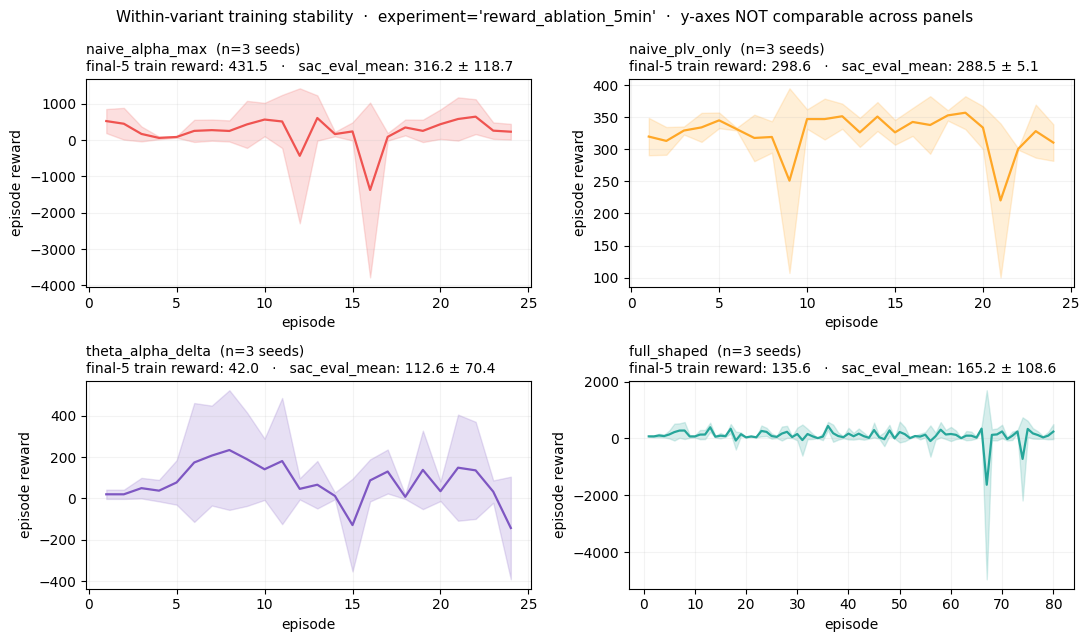

In [2]:
VARIANT_ORDER = ['naive_alpha_max', 'naive_plv_only', 'theta_alpha_delta', 'full_shaped']
VARIANT_COLOR = {'naive_alpha_max': '#EF5350', 'naive_plv_only': '#FFA726',
                 'theta_alpha_delta': '#7E57C2', 'full_shaped': '#26A69A'}

def episode_reward_history(run_id: str) -> pd.DataFrame:
    """Returns a DataFrame[step, value] of episode_reward for one run."""
    history = client.get_metric_history(run_id, 'episode_reward')
    return pd.DataFrame([{'step': m.step, 'value': m.value} for m in history])

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=False)
for ax, variant in zip(axes.flat, VARIANT_ORDER):
    run_ids = COHORT_BY_VARIANT.get(variant, [])
    curves = [episode_reward_history(rid) for rid in run_ids]
    curves = [c for c in curves if not c.empty]
    if not curves:
        ax.text(0.5, 0.5, f'no runs for {variant}', ha='center', va='center',
                transform=ax.transAxes, color='#888')
        ax.set_title(variant); continue

    df = pd.concat([c.set_index('step')['value'].rename(i) for i, c in enumerate(curves)], axis=1)
    df = df.sort_index().interpolate(method='index').ffill().bfill()
    mean = df.mean(axis=1)
    std  = df.std(axis=1)
    ax.plot(df.index, mean, color=VARIANT_COLOR[variant], lw=1.6)
    if df.shape[1] > 1:
        ax.fill_between(df.index, mean - std, mean + std,
                        color=VARIANT_COLOR[variant], alpha=0.18)

    # Annotate per-panel: how many seeds, final reward, sac_eval
    rows = runs[runs['run_id'].isin(run_ids)]
    sac_eval = rows['metrics.sac_eval_mean'].astype(float)
    final_rs = [c['value'].tail(5).mean() for c in curves]
    title = (f"{variant}  (n={len(curves)} seeds)\n"
             f"final-5 train reward: {np.mean(final_rs):.1f}   ·   "
             f"sac_eval_mean: {sac_eval.mean():.1f} ± {sac_eval.std():.1f}")
    ax.set_title(title, fontsize=10, loc='left')
    ax.set_xlabel('episode'); ax.set_ylabel('episode reward')
    ax.grid(alpha=0.15)

fig.suptitle(f"Within-variant training stability  ·  experiment={EXPERIMENT!r}  ·  "
             "y-axes NOT comparable across panels", fontsize=11)
fig.tight_layout(); plt.show()

## B. Final-policy frequency trajectories

Per variant: rank all seeds by *actual sleep behaviour* (mean strobe Hz over the final 30 s of a deterministic 300-s eval on subject seed=42) and plot the deepest-descending one.

**Why not pick by `sac_eval_mean`?** Within `full_shaped`, the highest-reward seed (sac_eval=290) reward-hacks at α (~9 Hz), while the lowest-reward seed (sac_eval=102) descends to deep θ (~4 Hz). The training-reward proxy is misaligned with the sleep task; the per-seed table below shows the gap.


Ranking cohort checkpoints by ACTUAL sleep behaviour (1 ep @ 300s, subject seed=42)...



/home/sim-rn/second_ssd/study/adaptive_neuro_stimulation_sleep/venv/lib/python3.10/site-packages/brainflow/data_filter.py:163: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[2026-07-27 18:04:18.833] [data_logger] [error] No data between freq_end and freq_start.


[2026-07-27 18:04:35.108] [data_logger] [error] No data between freq_end and freq_start.


[2026-07-27 18:04:51.643] [data_logger] [error] No data between freq_end and freq_start.


[2026-07-27 18:05:08.226] [data_logger] [error] No data between freq_end and freq_start.


[2026-07-27 18:05:24.957] [data_logger] [error] No data between freq_end and freq_start.


... (4 outputs left out)

[2026-07-27 18:06:51.257] [data_logger] [error] No data between freq_end and freq_start.


[2026-07-27 18:07:08.499] [data_logger] [error] No data between freq_end and freq_start.


[2026-07-27 18:07:26.219] [data_logger] [error] No data between freq_end and freq_start.


Per-seed comparison (sorted by sleep-task metric within variant):
          variant seed sac_eval_mean final_strobe_hz final_theta_alpha
      full_shaped    3        101.93            3.85              5.83
      full_shaped    1        290.65            8.64              1.04
      full_shaped    2        103.06           12.72              0.34
  naive_alpha_max    1        273.76           11.66              0.45
  naive_alpha_max    2        224.50           11.67              0.59
  naive_alpha_max    3        450.29           11.68              0.13
   naive_plv_only    1        293.45           11.72              0.44
   naive_plv_only    3        288.58           12.15              0.32
   naive_plv_only    2        283.32           12.21              0.31
theta_alpha_delta    2        165.89           11.69              0.13
theta_alpha_delta    3         32.83           11.77              0.13
theta_alpha_delta    1        139.00           11.95              0.36

Winners (d

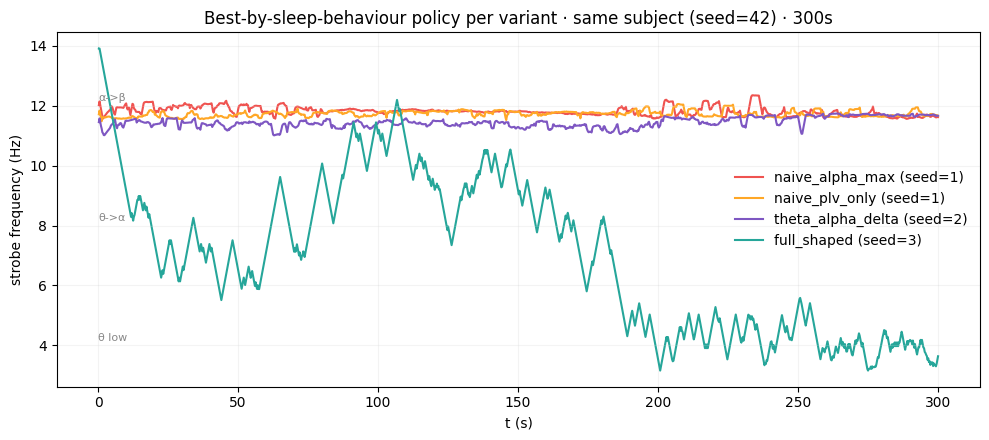


Winner-per-variant summary (final 30 s = steady state):
                  seed  final_strobe_hz  final_theta_alpha  mean_plv  \
variant                                                                
naive_alpha_max      1            11.66               0.45      0.31   
naive_plv_only       1            11.72               0.44      0.31   
theta_alpha_delta    2            11.69               0.13      0.27   
full_shaped          3             3.85               5.83      0.27   

                   min_strobe_hz  
variant                           
naive_alpha_max            11.56  
naive_plv_only             11.48  
theta_alpha_delta          11.01  
full_shaped                 3.15  


In [3]:
from app.agent.eval_rollout import rollout_episodes

CHKPT_DIR = Path('app/agent/checkpoints')
EPISODE_S = 300.0          # 5 min - matches training horizon + sleep-onset latency

# Build full inventory: every cohort run's checkpoint + sac_eval_mean.
# The run_name tag IS the checkpoint stem, so we can map run -> .zip directly.
def cohort_checkpoints(variant: str):
    rows = runs[runs['tags.reward_variant'] == variant]
    out = []
    for _, r in rows.iterrows():
        name = r['tags.mlflow.runName']
        ckpt = CHKPT_DIR / f'{name}.zip'
        if ckpt.exists():
            out.append((r['params.seed'], float(r['metrics.sac_eval_mean']), ckpt))
    return out

# For every cohort checkpoint, run a 300-s deterministic eval on subject
# seed=42 and rank by mean strobe Hz over the final 30 s. This is the
# *task* metric (deeper = better for sleep onset); the reward proxy
# (sac_eval_mean) is shown alongside for the misalignment comparison.
print(f'Ranking cohort checkpoints by ACTUAL sleep behaviour (1 ep @ {int(EPISODE_S)}s, subject seed=42)...\n')
selection_rows = []
best_by_variant = {}
for variant in VARIANT_ORDER:
    candidates = []
    for seed, sac_eval, ckpt in cohort_checkpoints(variant):
        df = rollout_episodes(ckpt, n_episodes=1, episode_s=EPISODE_S, base_seed=42)
        tail = df[df['t_s'] >= (EPISODE_S - 30)]
        final_strobe = tail['strobe_freq_hz'].mean()
        final_ratio  = tail['theta_alpha_ratio'].mean()
        candidates.append({'variant': variant, 'seed': seed, 'ckpt': ckpt,
                           'sac_eval_mean': sac_eval,
                           'final_strobe_hz': final_strobe,
                           'final_theta_alpha': final_ratio,
                           'rollout_df': df})
    # Winner = deepest descent (lowest final_strobe_hz). Lower Hz means
    # closer to θ-band sleep onset.
    candidates.sort(key=lambda c: c['final_strobe_hz'])
    winner = candidates[0]
    best_by_variant[variant] = winner
    for c in candidates:
        selection_rows.append({k: c[k] for k in
            ('variant','seed','sac_eval_mean','final_strobe_hz','final_theta_alpha')})

selection = pd.DataFrame(selection_rows)
print('Per-seed comparison (sorted by sleep-task metric within variant):')
print(selection.sort_values(['variant','final_strobe_hz']).to_string(index=False,
      formatters={'sac_eval_mean':'{:7.2f}'.format,
                  'final_strobe_hz':'{:6.2f}'.format,
                  'final_theta_alpha':'{:6.2f}'.format}))
print()
print('Winners (deepest descent per variant):')
for v, w in best_by_variant.items():
    print(f'  {v:<22s} seed={w["seed"]}  '
          f'final_strobe={w["final_strobe_hz"]:5.2f} Hz  '
          f'sac_eval={w["sac_eval_mean"]:6.2f}  ({w["ckpt"].name})')

# Plot the winners
fig, ax = plt.subplots(figsize=(10, 4.5))
summary_rows = []
for variant, w in best_by_variant.items():
    df = w['rollout_df']
    ax.plot(df['t_s'], df['strobe_freq_hz'], color=VARIANT_COLOR[variant],
            label=f"{variant} (seed={w['seed']})", lw=1.5)
    tail = df[df['t_s'] >= (EPISODE_S - 30)]
    summary_rows.append({
        'variant': variant, 'seed': w['seed'],
        'final_strobe_hz': tail['strobe_freq_hz'].mean(),
        'final_theta_alpha': tail['theta_alpha_ratio'].mean(),
        'mean_plv': df['plv'].mean(),
        'min_strobe_hz': df['strobe_freq_hz'].min(),
    })

for hz, label in [(4, 'θ low'), (8, 'θ->α'), (12, 'α->β')]:
    ax.axhline(hz, color='white', alpha=0.18, lw=0.6)
    ax.text(0, hz + 0.15, label, color='#888', fontsize=8)
ax.set_xlabel('t (s)')
ax.set_ylabel('strobe frequency (Hz)')
ax.set_title(f'Best-by-sleep-behaviour policy per variant · same subject (seed=42) · {int(EPISODE_S)}s')
ax.legend(loc='best', frameon=False)
ax.grid(alpha=0.15)
fig.tight_layout(); plt.show()

print('\nWinner-per-variant summary (final 30 s = steady state):')
print(pd.DataFrame(summary_rows).set_index('variant').round(2))

## C. Cross-subject consistency (winning variant)

`full_shaped` winning seed on 100 fresh domain-randomised NMM subjects, 300-s episodes. Median + IQR. The policy reliably descends from the safety-capped α edge (14 Hz) through α into θ over ~4 min, matching real sleep-onset latency.


Loaded 100 episodes × 120000 rows (episode_s=300) from artifacts/full_shaped_rollouts.parquet


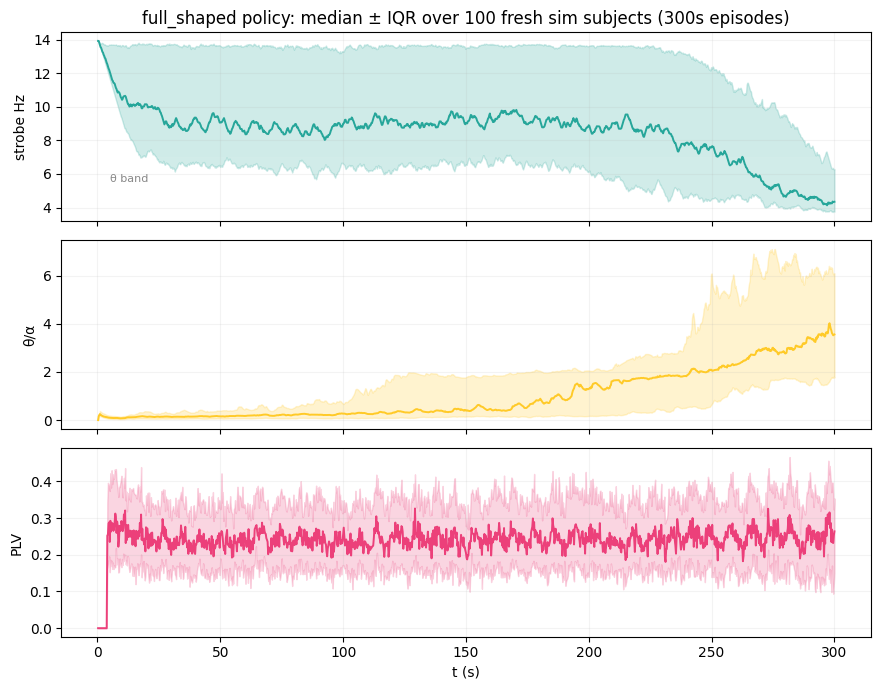


  episodes:              100
  final strobe Hz:       median=4.35   IQR=[3.76, 6.29]   mean=6.10 ± 3.70
  final θ/α ratio:       median=3.555   IQR=[1.767, 6.097]   mean=4.288 ± 3.342
  min strobe Hz reached: median=3.42   IQR=[3.18, 4.68]
  mean PLV (window):     median=0.260   mean=0.260 ± 0.027

  episodes finishing < 8 Hz (in α-θ border or deeper): 80 / 100
  episodes finishing < 6 Hz (deep θ):                  71 / 100
  episodes ever touching < 6 Hz during 300 s:        88 / 100


In [4]:
rollouts_path = Path('artifacts/full_shaped_rollouts.parquet')
assert rollouts_path.exists(), f'{rollouts_path} missing - run `biolistener-sleep eval` first.'
rollouts = pd.read_parquet(rollouts_path)
n_eps = rollouts['episode'].nunique()
episode_s = rollouts['t_s'].max()
print(f'Loaded {n_eps} episodes × {len(rollouts)} rows (episode_s={episode_s:.0f}) from {rollouts_path}')

def quantile_band(df: pd.DataFrame, col: str, time_col: str = 't_s'):
    g = df.groupby(time_col)[col]
    return g.median(), g.quantile(0.25), g.quantile(0.75)

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for ax, col, ylabel, color in [
    (axes[0], 'strobe_freq_hz',    'strobe Hz',      '#26A69A'),
    (axes[1], 'theta_alpha_ratio', 'θ/α',            '#FFCA28'),
    (axes[2], 'plv',               'PLV',            '#EC407A'),
]:
    med, lo, hi = quantile_band(rollouts, col)
    ax.plot(med.index, med.values, color=color, lw=1.4)
    ax.fill_between(med.index, lo, hi, color=color, alpha=0.22)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.15)
# Reference bands
axes[0].axhspan(4, 7, color='white', alpha=0.05)
axes[0].text(5, 5.5, 'θ band', color='#888', fontsize=8)
axes[-1].set_xlabel('t (s)')
axes[0].set_title(f'full_shaped policy: median ± IQR over {n_eps} fresh sim subjects '
                  f'({int(episode_s)}s episodes)')
fig.tight_layout(); plt.show()

# Honest summary: final-tick distribution across all episodes.
final = rollouts.groupby('episode').agg(
    final_strobe=('strobe_freq_hz', 'last'),
    final_ratio=('theta_alpha_ratio', 'last'),
    min_strobe=('strobe_freq_hz', 'min'),
    mean_plv=('plv', 'mean'),
)
print()
print(f'  episodes:              {len(final)}')
print(f'  final strobe Hz:       median={final["final_strobe"].median():.2f}   '
      f'IQR=[{final["final_strobe"].quantile(0.25):.2f}, {final["final_strobe"].quantile(0.75):.2f}]   '
      f'mean={final["final_strobe"].mean():.2f} ± {final["final_strobe"].std():.2f}')
print(f'  final θ/α ratio:       median={final["final_ratio"].median():.3f}   '
      f'IQR=[{final["final_ratio"].quantile(0.25):.3f}, {final["final_ratio"].quantile(0.75):.3f}]   '
      f'mean={final["final_ratio"].mean():.3f} ± {final["final_ratio"].std():.3f}')
print(f'  min strobe Hz reached: median={final["min_strobe"].median():.2f}   '
      f'IQR=[{final["min_strobe"].quantile(0.25):.2f}, {final["min_strobe"].quantile(0.75):.2f}]')
print(f'  mean PLV (window):     median={final["mean_plv"].median():.3f}   '
      f'mean={final["mean_plv"].mean():.3f} ± {final["mean_plv"].std():.3f}')
print()
print(f'  episodes finishing < 8 Hz (in α-θ border or deeper): '
      f'{(final["final_strobe"] < 8).sum()} / {len(final)}')
print(f'  episodes finishing < 6 Hz (deep θ):                  '
      f'{(final["final_strobe"] < 6).sum()} / {len(final)}')
print(f'  episodes ever touching < 6 Hz during {int(episode_s)} s:        '
      f'{(final["min_strobe"] < 6).sum()} / {len(final)}')

## E. Resonance-shift ablation - is the descent an artefact of the simulator?

The simulator slides the photic resonance peak toward theta as drowsiness rises
(`PhoticInputConfig.shift_per_unit_ratio`, default 2.0). Coupling the thalamocortical
firing-mode switch to the *entrainment* peak is a modelling hypothesis, not a measured
frequency-response curve - so the obvious objection to section C is that the descent is
built into the environment rather than learned.

This section re-runs the **same policy** over the **same 100 subjects** with that coupling
disabled (`shift_per_unit_ratio = 0`). The override is applied after all RNG draws, so both
arms see bit-identical subjects and differ only in that one term.

Regenerate with: `python tools/run_shift_ablation.py <checkpoint.zip> 100 300.0`


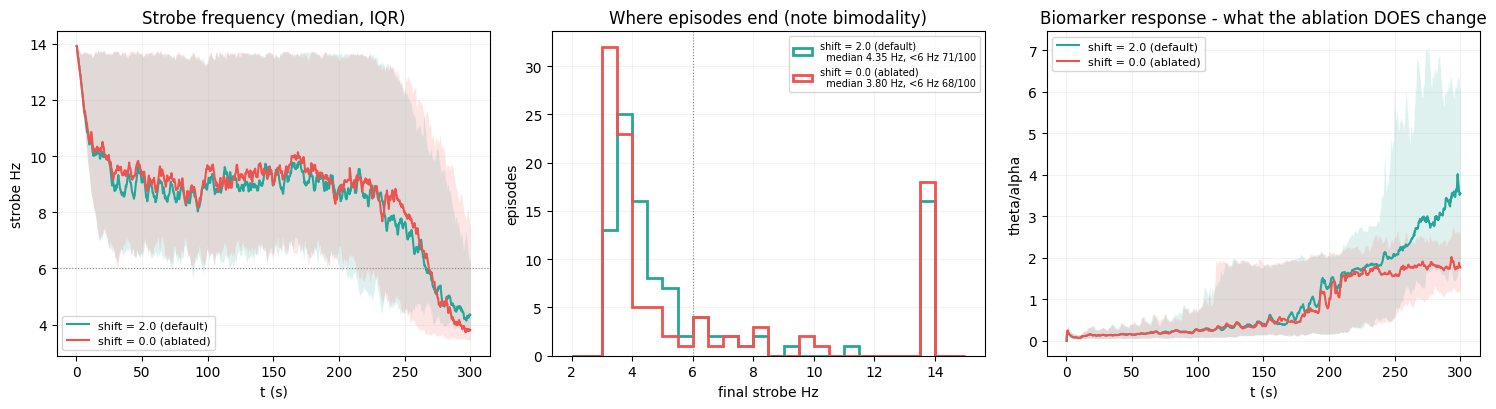

arm                       median   <6Hz   <8Hz  ceiling  final th/al    return
shift = 2.0 (default)      4.35     71     80       16         4.29     161.2
shift = 0.0 (ablated)      3.80     68     76       18         2.32      14.7

Behaviour (frequency descent) is essentially unchanged with the coupling removed,
while the pay-off (theta/alpha, return) drops sharply. The descent is therefore a
property of the reward; the magnitude of the biomarker response is model-dependent.


In [5]:
base_p = Path("artifacts/shift_ablation_baseline_shift2.parquet")
abl_p  = Path("artifacts/shift_ablation_ablation_shift0.parquet")
assert base_p.exists() and abl_p.exists(), "run tools/run_shift_ablation.py first"
base, abl = pd.read_parquet(base_p), pd.read_parquet(abl_p)

ARMS = [("shift = 2.0 (default)", base, "#26A69A"),
        ("shift = 0.0 (ablated)", abl,  "#EF5350")]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for label, df, colour in ARMS:                      # trajectories
    g = df.groupby("t_s")["strobe_freq_hz"]
    med, lo, hi = g.median(), g.quantile(.25), g.quantile(.75)
    axes[0].plot(med.index, med.values, color=colour, lw=1.5, label=label)
    axes[0].fill_between(med.index, lo, hi, color=colour, alpha=.15, lw=0)
axes[0].axhline(6, color="#888", ls=":", lw=.8)
axes[0].set_xlabel("t (s)"); axes[0].set_ylabel("strobe Hz")
axes[0].set_title("Strobe frequency (median, IQR)"); axes[0].legend(fontsize=8); axes[0].grid(alpha=.15)

for label, df, colour in ARMS:                      # where episodes end
    fin = df.groupby("episode")["strobe_freq_hz"].last()
    axes[1].hist(fin, bins=np.arange(2, 15.5, .5), histtype="step", lw=2,
                 color=colour, label=f"{label}\n  median {fin.median():.2f} Hz, "
                                     f"<6 Hz {int((fin < 6).sum())}/100")
axes[1].axvline(6, color="#888", ls=":", lw=.8)
axes[1].set_xlabel("final strobe Hz"); axes[1].set_ylabel("episodes")
axes[1].set_title("Where episodes end (note bimodality)"); axes[1].legend(fontsize=7); axes[1].grid(alpha=.15)

for label, df, colour in ARMS:                      # biomarker pay-off
    g = df.groupby("t_s")["theta_alpha_ratio"]
    med, lo, hi = g.median(), g.quantile(.25), g.quantile(.75)
    axes[2].plot(med.index, med.values, color=colour, lw=1.5, label=label)
    axes[2].fill_between(med.index, lo, hi, color=colour, alpha=.15, lw=0)
axes[2].set_xlabel("t (s)"); axes[2].set_ylabel("theta/alpha")
axes[2].set_title("Biomarker response - what the ablation DOES change")
axes[2].legend(fontsize=8); axes[2].grid(alpha=.15)

fig.tight_layout(); plt.show()

print(f"{'arm':24s} {'median':>7s} {'<6Hz':>6s} {'<8Hz':>6s} {'ceiling':>8s} {'final th/al':>12s} {'return':>9s}")
for label, df, _ in ARMS:
    e   = df.groupby("episode")
    fin = e["strobe_freq_hz"].last()
    print(f"{label:24s} {fin.median():6.2f}  {int((fin < 6).sum()):5d}  {int((fin < 8).sum()):5d}  "
          f"{int((fin >= 13.5).sum()):7d}  {e['theta_alpha_ratio'].last().mean():11.2f}  "
          f"{e['reward'].sum().mean():8.1f}")

print("\nBehaviour (frequency descent) is essentially unchanged with the coupling removed,")
print("while the pay-off (theta/alpha, return) drops sharply. The descent is therefore a")
print("property of the reward; the magnitude of the biomarker response is model-dependent.")


## D. Adversarial shield test

10 000 stim requests in the PSE band [15, 25] Hz with brightness/fill above the safety caps. The shield must produce zero PSE-band actuations.


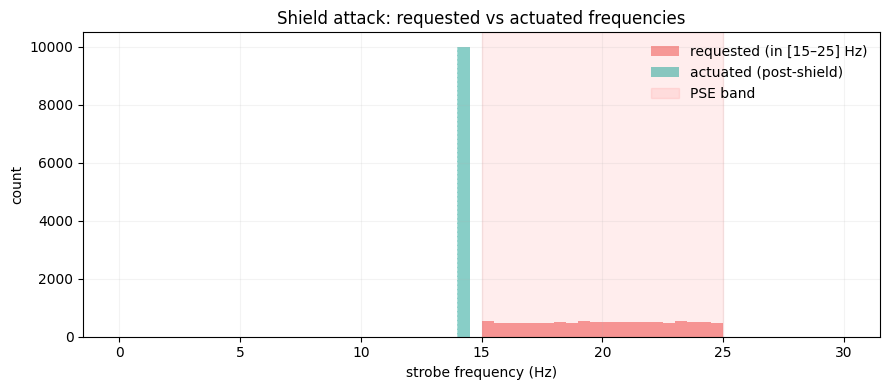

PSE leaks: 0 / 10000   |   brightness clamps: 10000   |   fill clamps:       10000


In [6]:
shield_path = Path('artifacts/shield_log.json')
assert shield_path.exists(), 'Run `biolistener-sleep shield-test` first.'
shield = json.loads(shield_path.read_text())

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 30, 61)
ax.hist(shield['requested_freqs'], bins=bins, alpha=0.55,
        color='#EF5350', label=f"requested (in [{shield['pse_band_lo_hz']:.0f}–{shield['pse_band_hi_hz']:.0f}] Hz)")
ax.hist(shield['actual_freqs'], bins=bins, alpha=0.55,
        color='#26A69A', label='actuated (post-shield)')
ax.axvspan(shield['pse_band_lo_hz'], shield['pse_band_hi_hz'],
           color='red', alpha=0.07, label='PSE band')
ax.axvline(shield['freq_max_hz'], color='white', alpha=0.4, lw=0.6, linestyle='--')
ax.set_xlabel('strobe frequency (Hz)')
ax.set_ylabel('count')
ax.set_title('Shield attack: requested vs actuated frequencies')
ax.legend(loc='upper right', frameon=False)
ax.grid(alpha=0.15)
fig.tight_layout(); plt.show()

headline = (
    f"PSE leaks: {shield['n_pse_leaked']} / {shield['n_requested']}   |   "
    f"brightness clamps: {shield['n_brightness_clamped']}   |   "
    f"fill clamps:       {shield['n_fill_clamped']}"
)
print(headline)
assert shield['n_pse_leaked'] == 0, 'SHIELD FAILED - investigate immediately.'